In [3]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Import data

In [1]:
path1 = "/mnt/c/users/helen/Desktop/190226/WT/WTaggregated_data.csv"
path2 = "/mnt/c/users/helen/Desktop/190226/MGS3/MGS3aggregated_data.csv"

In [4]:
df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)

In [7]:
df1["sample"] = "WT"
df2["sample"] = "MGS3"

combined_df = pd.concat(
    [df1, df2],
    ignore_index=True
)

In [13]:
# Clean data
combined_df.columns = combined_df.columns.str.strip().str.lower()
combined_df.iloc[:, 1:10] = combined_df.iloc[:, 1:10].apply(pd.to_numeric, errors="coerce")
df = combined_df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 59


In [15]:
combined_df.head()

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample
0,C2_MP_U2OS_fixed_WT_001.nd2_(series_05)_ROI_02...,452,6.838496,2.525441,0.891543,0.923505,4.900340,15.711590,18.807522,13.654867,WT
1,C2_MP_U2OS_fixed_WT_001.nd2_(series_06)_ROI_02...,373,5.316354,2.327790,0.901233,0.926065,3.888791,25.784152,29.471850,23.136729,WT
2,C2_MP_U2OS_fixed_WT_001.nd2_(series_08)_ROI_02...,360,5.705556,2.303457,0.925275,0.934900,3.649699,29.218538,33.625000,26.161111,WT
3,C2_MP_U2OS_fixed_WT_001.nd2_(series_10)_ROI_02...,268,7.865672,2.516320,0.893500,0.939220,4.567975,26.263477,31.720149,22.914179,WT
4,C2_MP_U2OS_fixed_WT_001.nd2_(series_11)_ROI_02...,49,33.448980,5.167265,0.775940,0.881285,16.881241,36.165190,58.693878,25.653061,WT


## Graphs

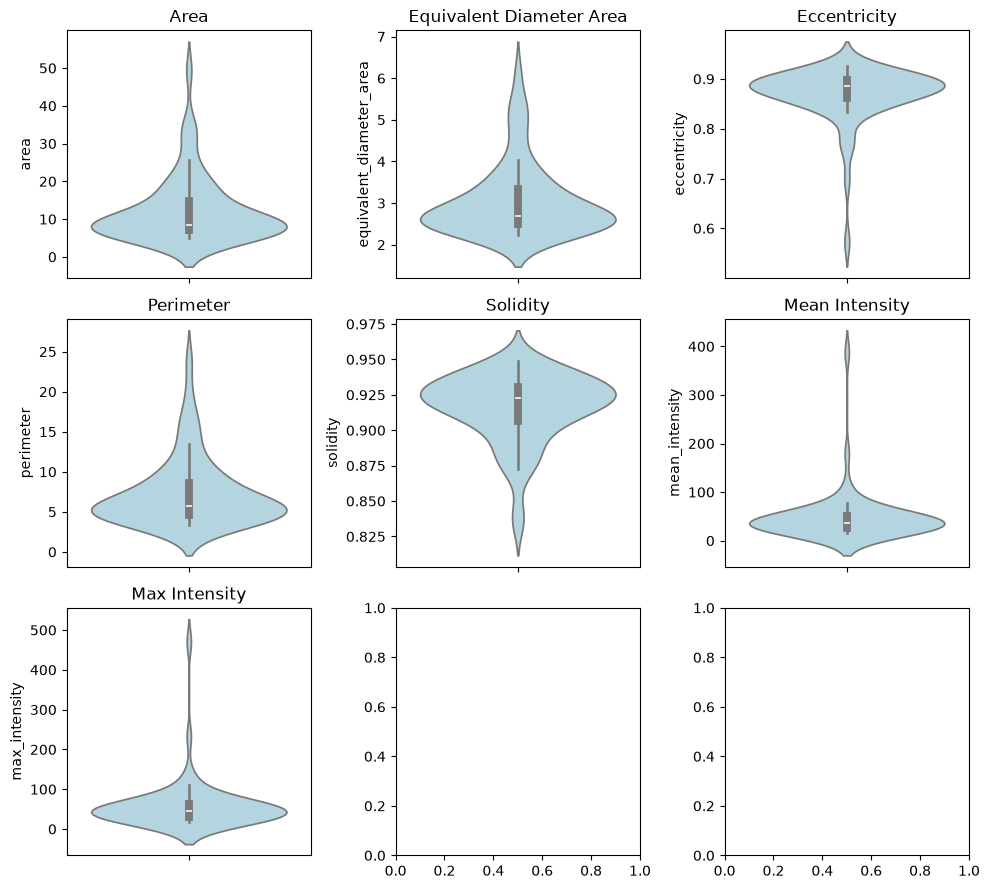

In [16]:
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

fig, axes = plt.subplots(3, 3, figsize=(10, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


# PCA

In [20]:
# Features for classification
features = [
    "area",
    "equivalent_diameter_area",
    #"eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

# Select features and scale them
pca_df = df.copy()

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

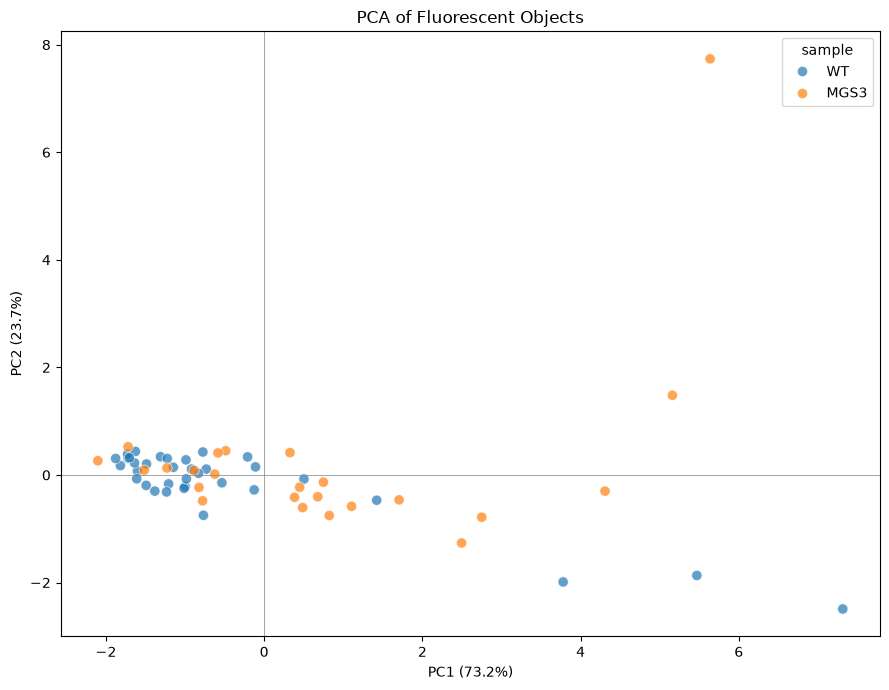

In [21]:
pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="sample",
    s=55,
    alpha=0.7
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of Fluorescent Objects")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)

plt.tight_layout()
plt.show()

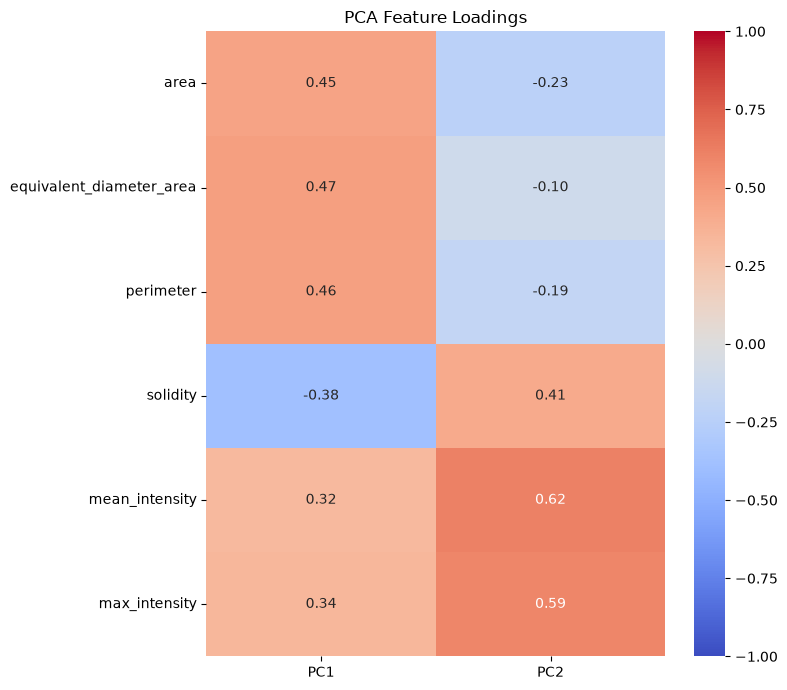

In [22]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [23]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

             PC1       PC2
sample                    
MGS3    0.679575  0.206783
WT     -0.465994 -0.141794


In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.patches import Ellipse
from scipy.stats import f


def plot_pca_centroids_ci(
    pca_df,
    group_col="sample",
    confidence=0.95,
    figsize=(9, 7)
):
    fig, ax = plt.subplots(figsize=figsize)

    groups = pca_df[group_col].dropna().unique()
    colors = sns.color_palette("Set2", len(groups))

    centroids = {}

    for group, color in zip(groups, colors):

        data = pca_df.loc[
            pca_df[group_col] == group,
            ["PC1", "PC2"]
        ].dropna()

        X = data.to_numpy()
        n = len(X)

        if n < 3:
            continue

        # Centroid
        centroid = X.mean(axis=0)
        centroids[group] = centroid

        # Covariance matrix
        cov = np.cov(X, rowvar=False)

        # 95% confidence ellipse for the mean
        p = 2

        scale = (
            p * (n - 1) / (n - p)
            * f.ppf(confidence, p, n - p)
        )

        # Covariance of the sample mean
        cov_mean = cov / n

        eigenvalues, eigenvectors = np.linalg.eigh(cov_mean)

        order = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[order]
        eigenvectors = eigenvectors[:, order]

        width, height = 2 * np.sqrt(
            np.maximum(eigenvalues, 0) * scale
        )

        angle = np.degrees(
            np.arctan2(
                eigenvectors[1, 0],
                eigenvectors[0, 0]
            )
        )

        # Plot observations
        ax.scatter(
            X[:, 0],
            X[:, 1],
            color=color,
            alpha=0.3,
            s=35,
            label=f"{group} (n={n})"
        )

        # Plot centroid
        ax.scatter(
            centroid[0],
            centroid[1],
            color=color,
            marker="X",
            s=250,
            edgecolor="black",
            linewidth=1.2,
            zorder=5
        )

        # Plot confidence ellipse
        ellipse = Ellipse(
            xy=centroid,
            width=width,
            height=height,
            angle=angle,
            facecolor=color,
            edgecolor=color,
            alpha=0.2
        )

        ax.add_patch(ellipse)

        border = Ellipse(
            xy=centroid,
            width=width,
            height=height,
            angle=angle,
            facecolor="none",
            edgecolor=color,
            linewidth=2
        )

        ax.add_patch(border)

    ax.axhline(0, color="gray", linestyle="--", alpha=0.3)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.3)

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(f"PCA — Centroids with {confidence:.0%} Confidence Ellipses")

    ax.legend(frameon=False)
    ax.grid(alpha=0.15)
    ax.set_aspect("equal", adjustable="datalim")

    plt.tight_layout()
    plt.show()

    return centroids

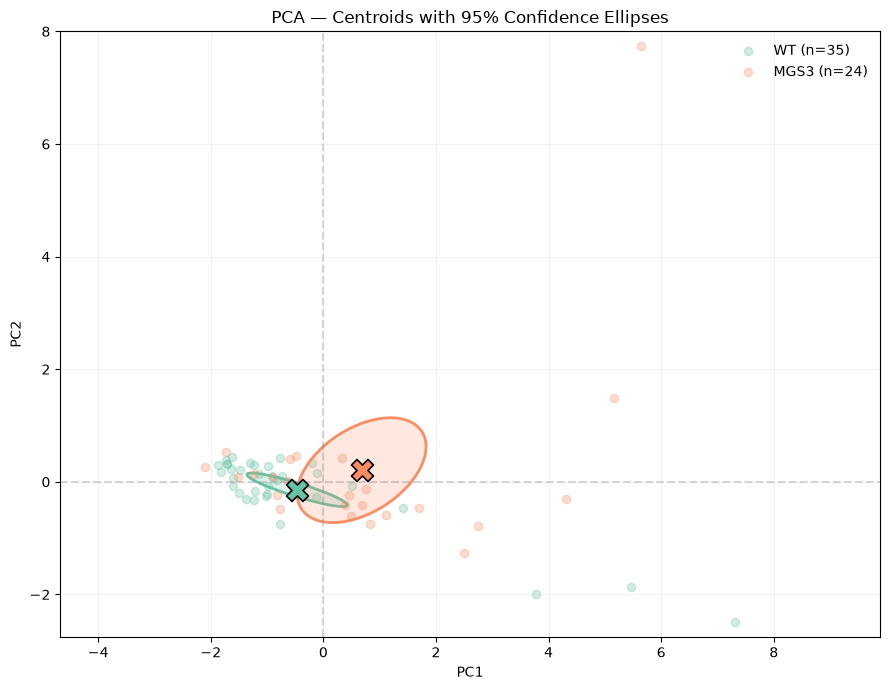

In [26]:
centroids = plot_pca_centroids_ci(
    pca_df,
    group_col="sample",
    confidence=0.95
)